# 03 · 学习计划和进度：小节记录、周统计与高频写入


## 本章范围与学习路线

第02章已经建立用户与课程的课表关系，但 `learned_sections` 仍为0，最近学习小节和时间也没有真实数据。本章让课表能够回答：用户学到了哪里、完成了多少小节、本周计划是否达标。

**来源**：[网盘分享](https://pan.baidu.com/s/1dcVvDI-sWN68Xzcsz1LSAQ?pwd=w7bj) 中 `day03-学习计划和进度/讲义/day03-学习计划和进度.pptx`（47页），以及 [官方 day03 讲义](https://my.feishu.cn/wiki/wikcn9d7rcLIt1yNrT3Vd6YM2kf)。整理日期：2026-10-09。PPT后半部分已经包含高并发写优化，在线 day03 则以接口实现、练习和面试题为主，因此两部分一起整理。

| 顺序 | 要解决的问题 | 核心产物 |
| --- | --- | --- |
| 1 | 怎样判断用户学过、学完 | 小节学习记录与完成规则 |
| 2 | 怎样断点续播 | 查询记录、定期上报播放位置 |
| 3 | 怎样更新整门课的进度 | 第一次完成计数、课程状态变化 |
| 4 | 怎样督促每周学习 | 学习计划、按周聚合与分页 |
| 5 | 怎样降低高频上报的数据库压力 | Redis 合并写、延迟检测 |

Java/SQL示例用于理解设计。标注“补充”“改进示例”的部分是对边界问题的解释，并非照抄课件中的完整实现。网盘另有 `DelayTask.java`、`LearningRecordDelayTaskHandler.java` 和 `com` 目录，Java附件下载要求登录，未取得其源码；延迟任务代码按可读PPT流程给出示意实现。


## 课程、章、小节与课表的关系

统计学习进度前先确定最小单位。**课程**是用户购买的内容，**章（chapter）**只是分组，**小节（section）**才有视频或考试。每门课包含多个章，每章包含多个小节。**课表（lesson）**是一个用户与一门课程的报名关系。

```text
课程 courseId=100
├─ 第一章
│  ├─ 视频 sectionId=101
│  ├─ 视频 sectionId=102
│  └─ 考试 sectionId=103
└─ 第二章
   └─ 视频 sectionId=104

用户A的课表 lessonId=800 → courseId=100
用户B的课表 lessonId=900 → courseId=100
每张课表各自拥有小节学习记录，进度互不影响。
```

| 标识 | 表达的对象 | 常见误用 |
| --- | --- | --- |
| `courseId` | 公共课程内容 | 当成某用户的课表ID |
| `lessonId` | 某用户报名该课程的关系 | 当成视频ID |
| `sectionId` | 公共课程中的小节 | 单独作为所有用户共享的进度键 |
| 学习记录 `id` | 某用户某小节的一条进度记录 | 每15秒都新增一行 |

一条学习记录持续更新，第一次完成时间保留。章本身不计课时，视频和考试小节都计入课程小节总数。


## 播放位置、小节完成与课程完成

续播需要精确的播放位置，进度统计需要稳定的完成标记，两者不能互相替代。

| 信息 | 含义 | 例子 |
| --- | --- | --- |
| `moment` | 视频当前播放到第几秒 | 总长600秒，当前播放到180秒 |
| `finished` | 当前小节是否已达到完成规则 | 达到完成阈值后保持true |
| `learned_sections` | 课程累计完成的小节数 | 10个小节中已经完成3个 |
| 课程 `status` | 整门课的学习状态 | 全部小节完成后为已学完 |

课程规则：视频播放进度达到一半算完成小节，考试提交算完成小节。在线讲义文字和PPT常写“超过50%”，但实现使用 `moment * 2 >= duration`，所以本笔记采用**达到50%**的代码口径。

```java
// 改进示例：先验证duration > 0、0 <= moment <= duration
boolean reachesHalf = 2L * moment >= duration;
```

使用 `2L` 避免int乘法溢出。总长601秒时，播放到300秒尚未完成，301秒达到阈值。

> 播放位置只描述当前位置。用户拖到视频中间也可能达到阈值，它不证明实际连续观看了这么久。本课程规则适用于学习体验，严格观看时长或防作弊需要额外记录有效播放区间。

用户重复播放或回退时，`moment` 可以变化，但 `finished` 不应从true退回false。全部计入课程的小节完成，才把课程标记为已学完。


## 学习计划与学习状态

学习计划让用户指定每周目标，系统按周统计完成情况。它保存在 `learning_lesson`，无需另外新增一张计划表。

| 字段 | 用途 | 值的含义 |
| --- | --- | --- |
| `week_freq` | 每周目标小节数 | 每周3天、每天2节，对应6 |
| `plan_status` | 是否有进行中的计划 | 0无计划，1计划中 |
| `status` | 整门课学习状态 | 0未学习，1学习中，2已学完，3已失效 |

`PlanStatus.NO_PLAN`、`PlanStatus.PLAN_RUNNING` 与 `LessonStatus` 属于两套枚举。计划是否存在，与课程是否开始学习是两件事，查询计划不能只筛选 `status=LEARNING`，还需要包含已经创建计划但尚未开始的课程。

创建计划针对当前用户的有效课程。频率表示**每周小节数**，不是天数，也不是分钟数。课程完成或过期后是否继续保留计划历史，需要明确产品规则，本章列表只显示未学习或学习中的进行中计划。


## 四项接口与网关路径

围绕用户学习顺序，本章包含四项接口。下面是学习服务内部路径，经过网关时沿用第02章的 `/ls` 前缀。

| 功能 | 方法与内部路径 | 请求 | 返回 |
| --- | --- | --- | --- |
| 查询课程学习记录 | `GET /learning-records/course/{courseId}` | 课程ID | `LearningLessonDTO`，包括课表、最近小节及记录列表 |
| 提交学习记录 | `POST /learning-records` | `LearningRecordFormDTO` | 无业务返回值 |
| 创建/修改学习计划 | `POST /lessons/plans` | 课程ID与每周频率 | 无业务返回值 |
| 查询我的学习计划 | `GET /lessons/plans` | `PageQuery` | `LearningPlanPageVO`，包括汇总和分页列表 |

例如浏览器请求 `/ls/learning-records/course/100`，Controller中的路径仍是 `/learning-records/course/{courseId}`，Feign客户端也不添加网关前缀。

查询学习记录接口也是课程详情/学习页面聚合用户进度所需的内部能力。课程目录、小节名称和内容来自课程服务，学习服务返回该用户的记录，调用方按 `sectionId` 合并。


## 提交记录的DTO与参数校验

表单负责接收用户本次学习的信息，登录用户ID由服务端获取，不能由前端任意指定。

| 字段 | 类型 | 含义/校验 |
| --- | --- | --- |
| `lessonId` | Long | 非空，当前用户的有效课表 |
| `sectionId` | Long | 非空，属于该课表对应课程 |
| `sectionType` | SectionType | 1视频，2考试，只允许已定义类型 |
| `duration` | Integer | 视频总时长，秒，视频时必须大于0 |
| `moment` | Integer | 本次播放位置，秒，视频时必须非空且在合法范围 |
| `commitTime` | LocalDateTime | 本次提交时间，需明确可信来源与时钟规则 |

```json
{
  "lessonId": 800,
  "sectionId": 101,
  "sectionType": 1,
  "duration": 600,
  "moment": 315,
  "commitTime": "2026-10-09T10:00:00"
}
```

原DTO使用 `@NotNull`、自定义 `@EnumValid` 等注解，但 `duration`、`moment`、`commitTime` 并没有完整校验，原提交Controller也未展示 `@Valid`。**补充**：校验注解要配合 `@Valid @RequestBody` 生效，视频与考试的条件校验放到分组校验或业务层。考试无需套用视频时长判断。

时长、小节类型应由课程元数据确认，考试完成应以可信考试结果为准，不能仅凭客户端声称 `sectionType=2` 就增加已学小节数。


## learning_record 表结构与版本差异

学习记录保存某用户某小节的最新进度，而不是每次心跳的历史事件。下列DDL以PPT第14页为准，补全了在线讲义SQL缺少但后续代码会使用的 `finish_time`。

```sql
CREATE TABLE IF NOT EXISTS learning_record (
  id bigint NOT NULL COMMENT '学习记录id',
  lesson_id bigint NOT NULL COMMENT '对应课表id',
  section_id bigint NOT NULL COMMENT '对应小节id',
  user_id bigint NOT NULL COMMENT '用户id',
  moment int DEFAULT 0 COMMENT '当前播放位置，秒',
  finished bit(1) NOT NULL DEFAULT b'0' COMMENT '是否完成',
  create_time datetime NOT NULL DEFAULT CURRENT_TIMESTAMP,
  finish_time datetime DEFAULT NULL COMMENT '第一次完成时间',
  update_time datetime NOT NULL DEFAULT CURRENT_TIMESTAMP
    ON UPDATE CURRENT_TIMESTAMP,
  PRIMARY KEY (id),
  UNIQUE KEY idx_user_id (user_id, section_id),
  KEY idx_update_time (update_time),
  KEY idx_lesson_id (lesson_id)
) ENGINE=InnoDB DEFAULT CHARSET=utf8mb4
  COLLATE=utf8mb4_0900_ai_ci COMMENT='学习记录表';
```

| 项目 | 在线 day03 DDL | PPT第14页 |
| --- | --- | --- |
| 第一次完成时间 | 缺少 `finish_time` | 包含可空 `finish_time` |
| 用户索引 | 普通 `(user_id)` | 唯一 `(user_id, section_id)` |
| 课表索引 | 普通 `(lesson_id, section_id)` | 普通 `(lesson_id)` |

**补充**：PPT唯一约束假设小节ID全局唯一，且同一用户同一小节只保留一份进度。如果重新报名会产生独立学习周期，要评估改用唯一 `(lesson_id, section_id)`。索引是业务约束的一部分，不能无条件同时添加两种唯一规则。

`utf8mb4_0900_ai_ci` 是MySQL8的排序规则。`CREATE TABLE IF NOT EXISTS` 不会自动修改已经存在的旧表，实际开发要检查DDL并使用迁移语句。此处只写笔记，不在数据库执行。


## 三种时间与统计口径

同一个视频可能先看30秒，第二天达到完成阈值，第三天又重看。统计本周新完成数量，需要保留**第一次完成时间**。

| 字段 | 记录什么 | 能否用于本周完成统计 |
| --- | --- | --- |
| `create_time` | 首次建立学习记录 | 不能代表学完时间 |
| `finish_time` | 第一次从未完成变为完成 | 可以，配合 `finished=true` |
| `update_time` | 最近数据库更新 | 重看、延迟落库都会改变，不能代替完成时间 |
| 课表 `latest_learn_time` | 该课程最近学习活动 | 用于最近学习展示/排序 |

例：周日首次看20%，周一达到50%，周二重看，完成数应计入周一所在周一次。周三再次达到50%不再增加计数，也不覆盖 `finish_time`。

缓存延迟写入后，数据库 `update_time` 主要反映落库时间。若要保留真实学习活动时间，应保存经过校验的提交时间或服务端接收时间。


## 基础代码与 SectionType 枚举

课程要求从DEV创建 `feature-learning-records` 分支，用MyBatis-Plus生成PO、Mapper、Service、Controller，再补充业务方法。笔记仓库没有对应后端工程，因此这里只保留步骤与职责。

```text
LearningRecordController        HTTP入口、表单校验
ILearningRecordService          查询、提交记录的业务契约
LearningRecordServiceImpl       小节记录与课表更新
LearningRecordMapper           持久化与聚合SQL
LearningLessonServiceImpl       创建计划、查询计划
```

`SectionType.VIDEO=1`、`SectionType.EXAM=2` 把数字转换成可读业务类型。讲义枚举使用 `@EnumValue` 对接MyBatis-Plus，`@JsonValue`/`@JsonCreator` 处理JSON转换，配合项目公共的 `BaseEnum`。

**勘误**：在线说明写“学习记录中有 section_type 字段”，但展示的表结构没有此列；类型存在于提交DTO并来自课程小节元数据。不要根据一句说明擅自认定当前数据库已包含该字段。


## 查询学习记录与断点续播

续播查询先找到当前用户在该课程的课表，再查询该课表下的学习记录。不能按 `courseId` 查询全体学员进度。

```java
// 按讲义主流程整理，补充空课表与有效期判断
Long userId = UserContext.getUser();
LearningLesson lesson = lessonService.queryByUserAndCourseId(userId, courseId);
if (lesson == null || (lesson.getExpireTime() != null
        && !lesson.getExpireTime().isAfter(LocalDateTime.now()))) {
    return null;
}
List<LearningRecord> records = lambdaQuery()
        .eq(LearningRecord::getLessonId, lesson.getId()).list();
LearningLessonDTO dto = new LearningLessonDTO();
dto.setId(lesson.getId());
dto.setLatestSectionId(lesson.getLatestSectionId());
dto.setRecords(BeanUtils.copyList(records, LearningRecordDTO.class));
return dto;
```

返回的 `id` 是课表ID，`latestSectionId` 是最近学习小节，`records` 每项提供 `sectionId`、`moment`、`finished`。未学习的小节可以没有记录，页面按课程目录补成未学状态。

> 原讲义分析提出“不存在或过期返回空”，代码却直接使用 `lesson.getId()`，会在未报名时空指针，也没有显式有效期校验。不能把分析中提出的规则视为代码已经实现。

**补充**：缓存优化后查询应优先读取有效的Redis进度，或将数据库列表与同一课表的缓存记录按 `sectionId` 合并。只读数据库会在用户仍播放或刚切换设备时取到旧位置。


## 提交学习记录的完整业务流程

一次提交既维护小节记录，又可能推进课程汇总。二者应围绕同一个“本次是否首次完成”结果协作。

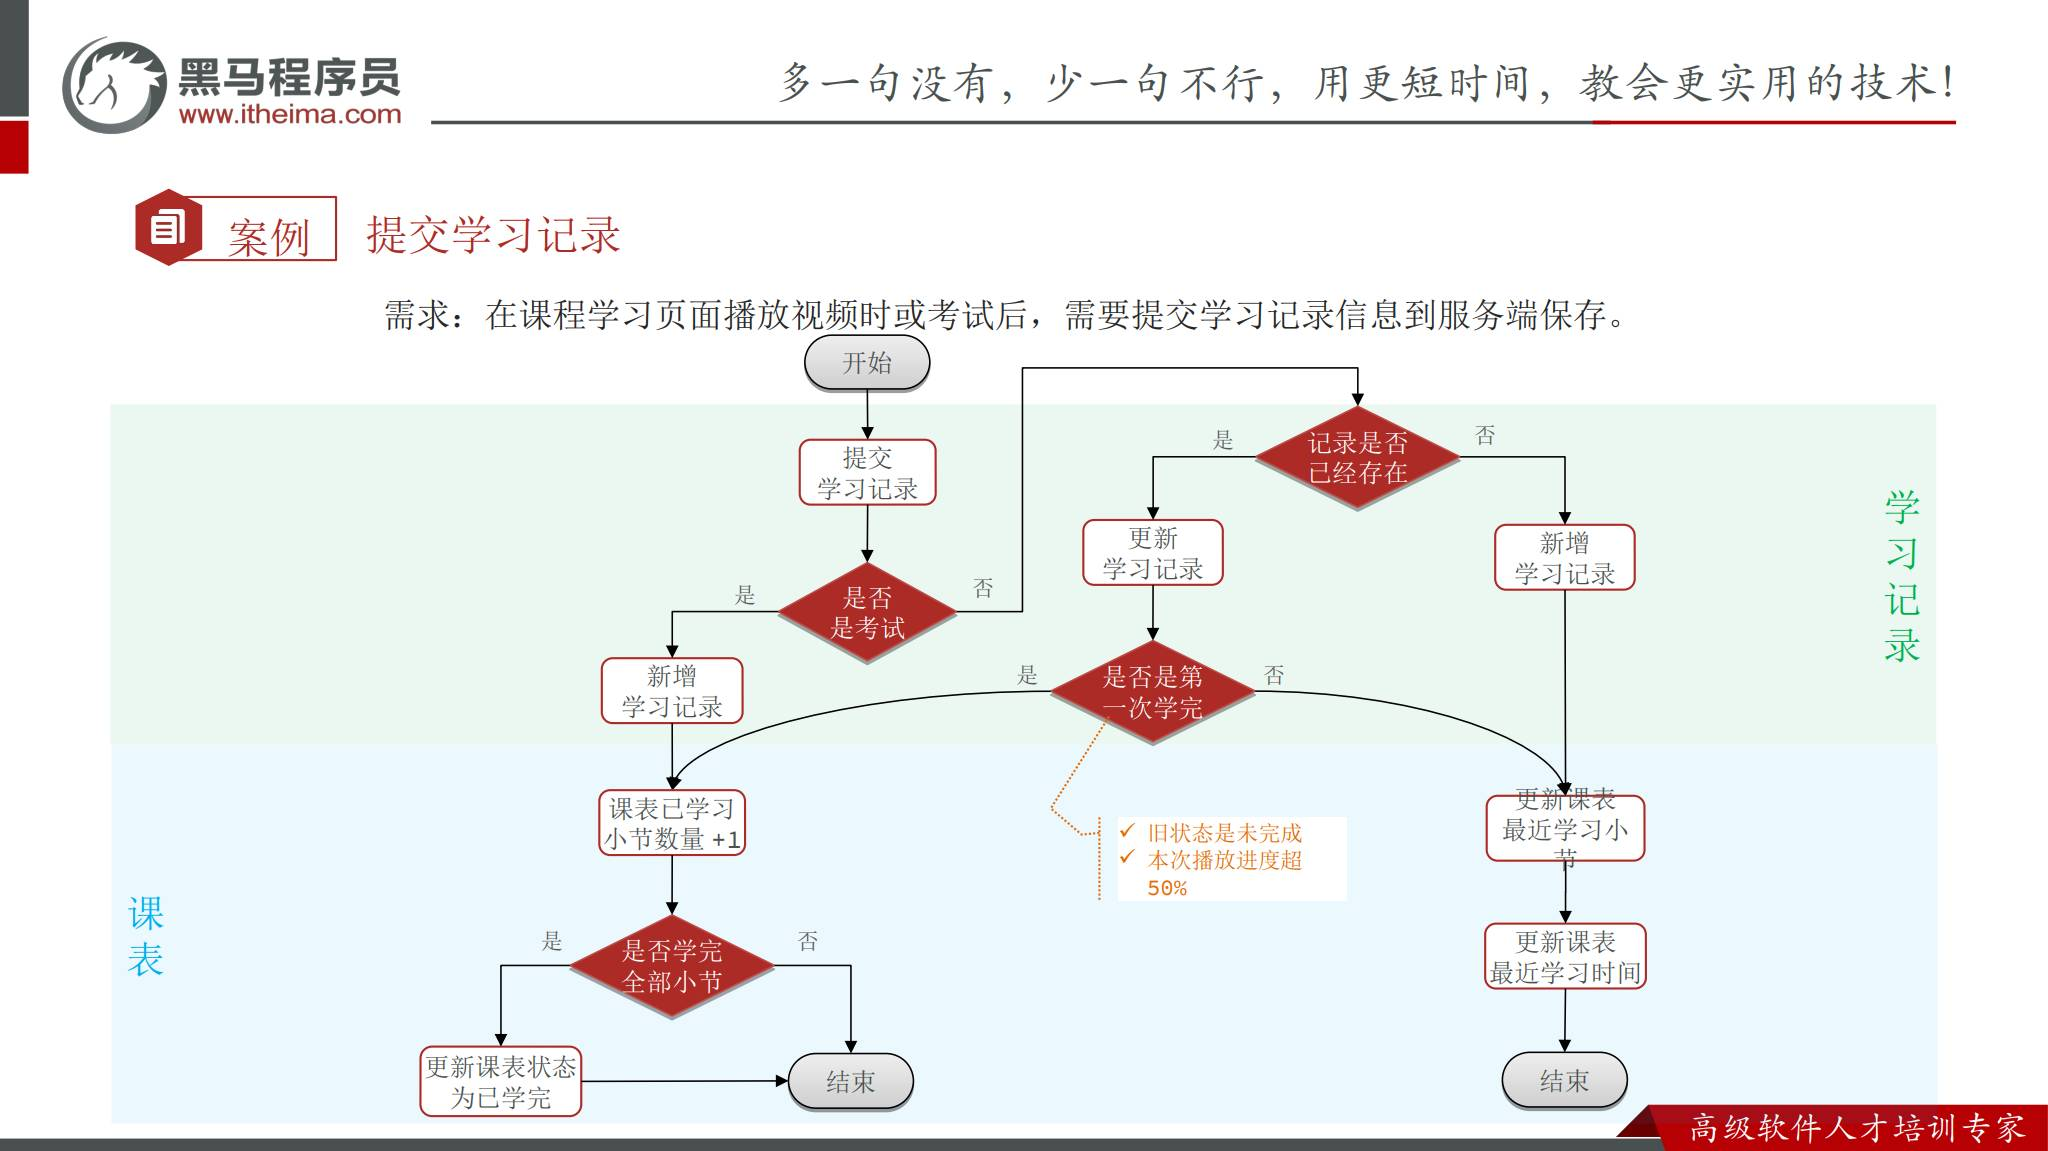

*来源：本章PPT第20页。图中首次新增视频记录与后续更新分开处理。*

| 阶段 | 动作 | 输出 |
| --- | --- | --- |
| 1 | 获取当前用户并校验课表、小节、有效期 | 可操作的课表与可信元数据 |
| 2 | 按视频/考试处理小节记录 | `newlyFinished`，本次是否首次完成 |
| 3 | 更新最近小节和学习时间 | 续播入口与课表排序依据 |
| 4 | 首次完成才增加 `learned_sections` | 累计完成小节数 |
| 5 | 判断是否全部完成 | 更新课程状态，必要时记录课程完成时间 |

讲义 `addLearningRecord` 在Service方法上使用 `@Transactional`，把学习记录和课表的数据库写入放在本地事务里。返回的布尔值原名 `finished`，但其真实含义是**本次新完成**，并不是该记录当前已经完成；理解这一点才能避免重看重复累加。


## 视频记录的首次新增与持续更新

讲义先按 `(lessonId, sectionId)` 查旧记录。不存在则新增，存在则更新播放位置，并计算首次完成。

```java
// 讲义中更新已有视频记录的核心逻辑
boolean newlyFinished = !old.getFinished()
        && 2L * form.getMoment() >= form.getDuration();
lambdaUpdate()
    .set(LearningRecord::getMoment, form.getMoment())
    .set(newlyFinished, LearningRecord::getFinished, true)
    .set(newlyFinished, LearningRecord::getFinishTime, form.getCommitTime())
    .eq(LearningRecord::getId, old.getId())
    .update();
return newlyFinished;
```

| 旧状态 | 本次进度 | 当前完成状态 | 本次计数 |
| --- | --- | --- | --- |
| 未完成 | 30% | false | 不增加 |
| 未完成 | 50% | true | 增加1 |
| 已完成 | 80% | true | 不增加 |
| 已完成 | 回退到20% | true | 不增加 |

**原代码限制**：首次新增视频记录直接返回false，没有判断首条请求是否已达到阈值。讲义DTO注释预期第一次提交 `moment=0`，但这是客户端约定，不能覆盖首条请求丢失、拖动或补报场景。改进时新增和更新都应处理完成条件。

上面的读旧记录再更新仅适合解释单请求流程。并发情况下，两次请求可能同时读到false，不能据此保证只计一次，原子处理见后文。


## 考试记录与重复提交

课程把“提交考试”视为完成该考试小节，学习服务记录 `finished=true` 和首次完成时间，然后推进课程汇总。

```java
// 讲义的考试分支，省略对象转换细节
record.setUserId(userId);
record.setFinished(true);
record.setFinishTime(form.getCommitTime());
save(record);
return true;
```

讲义假定考试只参加一次，因此直接插入并返回true。真实接口仍可能遇到用户重复点击、网络重试、消息重复投递。唯一索引能拒绝重复行，但重复异常不等于业务已经正确幂等。

**补充**：使用可信考试提交ID去重，或基于已存在的小节记录判断状态转移，只有“未完成变为完成”的请求增加课表计数。同一提交重试应得到成功或明确的已处理结果，不能再次累加。


## 课表汇总、课程状态与事务

小节记录是明细，课表 `learned_sections` 是便于查询的冗余汇总。完成一个新小节时，应在数据库执行自增，避免Java读取旧值再覆盖造成丢失更新。

```sql
UPDATE learning_lesson
SET learned_sections = learned_sections + 1
WHERE id = :lessonId;
```

讲义首次完成时调用 `courseClient.getCourseInfoById(courseId, false, false)` 获取课程总小节数，用 `旧计数 + 1 >= sectionNum` 判断已学完，随后通过 `setSql` 自增并更新状态。

| 课程状态 | 触发 |
| --- | --- |
| 未学习变为学习中 | 首次有效学习活动 |
| 学习中变为已学完 | 已完成数量达到课程总小节数 |
| 未学习/学习中变为已失效 | 超过有效期，由任务和入口校验共同保障 |

**原代码限制**：`set(!finished, latestSectionId/LatestLearnTime, ...)` 只在本次没有新完成时更新最近信息，首次完成考试/视频时最近信息可能滞后。状态启动条件 `learnedSections==0` 也不能完整表达“第一次观看”，因为用户可能看了很多节但都未达到一半。

**补充**：最近学习信息按有效活动更新，并对乱序请求限制时间倒退。课程完成时间仅首次完成时写入。两节并发完成可能都用旧计数判断“尚未学完”，最终计数已满但状态未完成，可在同一事务锁定课表行后更新，或在自增后基于受保护的新计数判定。

本地 `@Transactional` 保护MySQL内的两类写入，不会自动回滚Redis或远程课程调用。远程查询放在事务中会延长持锁时间，课程元数据可先查询并校验，再进入数据库事务。


## 首次完成的幂等与并发控制

重复请求最关键的保证是：**一个小节只能贡献一次完成增量**。幂等指同一操作重复执行，结果仍与执行一次相同。

反例：请求A、B同时读到 `finished=false`，两者都计算 `newlyFinished=true`，即使课表自增没有丢失，也会从1错误增加到3。

```sql
-- 改进示例：已有记录的完成状态通过条件更新竞争
UPDATE learning_record
SET finished = b'1', finish_time = :firstFinishTime, moment = :moment
WHERE id = :recordId AND finished = b'0';
-- 只有影响1行的请求获得“首次完成”的资格。
-- 同一事务内，该请求才自增课表已完成数。
```

普通位置更新与首次完成转换要分别处理：条件更新影响0行，可能是别人已完成，仍可根据有效请求版本更新续播位置，但不要再次统计完成。

| 场景 | 需要的保障 |
| --- | --- |
| 同时创建第一条记录 | 唯一约束、冲突后重查/幂等处理 |
| 同一节并发到达完成阈值 | 条件更新或行锁，依据影响行数计数 |
| 不同小节同时完成 | 课表计数原子增加，完成状态判定避免旧值 |
| 考试重复提交 | 可信业务标识去重，首次完成才计数 |

这是在原课程单请求逻辑基础上的补充设计。不能只加 `@Transactional` 就声称所有并发问题已解决，事务并不默认串行执行全部请求。


## 创建计划的实际实现与字段名对齐

“创建计划”实际更新已经存在的课表，查询条件同时包含当前用户和课程ID，避免修改别人的计划。

```java
// 在线讲义使用freq作为DTO属性
public void createLearningPlan(Long courseId, Integer freq) {
    Long userId = UserContext.getUser();
    LearningLesson lesson = queryByUserAndCourseId(userId, courseId);
    AssertUtils.isNotNull(lesson, "课程信息不存在！");
    LearningLesson update = new LearningLesson();
    update.setId(lesson.getId());
    update.setWeekFreq(freq);
    if (lesson.getPlanStatus() == PlanStatus.NO_PLAN) {
        update.setPlanStatus(PlanStatus.PLAN_RUNNING);
    }
    updateById(update);
}
```

讲义DTO要求 `courseId` 非空且大于0，`freq` 非空且范围1～50，Controller使用 `@Valid`。其 `courseId` 注释写“课程表id”是错误的，实际按课程ID查询课表。

| 位置 | 每周频率字段 |
| --- | --- |
| PPT接口表 | `weekFreq` |
| 在线Java DTO | `freq`，Controller调用 `getFreq()` |
| 数据库/PO/展示VO | `week_freq` / `weekFreq` |

联调时必须以实际DTO及前端请求为准。若接口约定传 `weekFreq`，就统一DTO字段或显式添加JSON映射，不能默认 `weekFreq` 会自动绑定到 `freq`。

**补充**：校验课程仍有效、尚未完成，以及更新是否成功。重复设置同一频率应保持相同结果。在线此处展示的旧 `learning_lesson` DDL遗漏 `week_freq`、`plan_status`，不要照抄它替换第02章已整理的表结构。


## 学习计划返回值与数据来源

计划页面包含全局汇总和每门课列表，它们来自不同的表与服务。

| 字段 | 含义 | 来源 |
| --- | --- | --- |
| `weekPoints` | 本周学习积分 | 课程示例保留TODO，后续积分功能 |
| `weekFinished` | 本周首次完成小节总数 | `learning_record` 计数 |
| `weekTotalPlan` | 进行中课程的每周目标总数 | `learning_lesson.week_freq` 求和 |
| `courseId` / `learnedSections` / `latestLearnTime` | 课程ID、累计进度、最近活动 | 当前用户课表 |
| `courseName` / `sections` | 课程名称、总小节数 | 课程服务 |
| `weekLearnedSections` | 某课本周首次完成小节数 | 记录按 `lesson_id` 分组 |
| `weekFreq` | 某课每周目标 | 课表 |
| `total` / `pages` / `list` | 分页元信息与当前页 | `LearningPlanPageVO.pageInfo(...)` |

PPT第11页写 `weekSections`，第24页和在线代码使用 `weekLearnedSections`，本笔记采用后者。`sections` 表示课程总小节数，不是章数。

总览不能只把当前页加起来。例如共有12门计划课程、每页5门，`weekTotalPlan` 应覆盖全部有效计划，而非当前5门。积分TODO不代表已实现，可返回明确的未接入状态或按接口约定占位。


## 本周时间窗口与完成计数

统计按完成时间划分周，而不是更新时间。时区和一周起点要固定，本课程使用周范围辅助方法 `DateUtils.getWeekBeginTime/getWeekEndTime`。

**改进示例**：采用周一00:00到下周一00:00的左闭右开区间 `[begin, nextBegin)`，避免漏掉刚好处于边界的记录。

```java
LocalDate today = LocalDate.now(ZoneId.of("Asia/Shanghai"));
LocalDate monday = today.with(
    TemporalAdjusters.previousOrSame(DayOfWeek.MONDAY));
LocalDateTime begin = monday.atStartOfDay();
LocalDateTime nextBegin = monday.plusWeeks(1).atStartOfDay();
```

```sql
SELECT COUNT(*)
FROM learning_record
WHERE user_id = :userId AND finished = b'1'
  AND finish_time >= :begin AND finish_time < :nextBegin;
```

原例使用 `gt(begin)`、`lt(end)`，会排除恰好等于begin的记录。若end代表周日最后一秒，数据库精度差异也容易造成遗漏，使用下周起点更清晰。

> 在线实现的 `weekFinished` 统计当前用户本周全部完成记录，而计划列表只显示进行中的未完成课程，因此某课本周学完后退出列表，其完成数仍保留在汇总里。这是实现口径，不能声称“汇总等于当前计划列表之和”。如产品要求仅统计某组计划课程，应给两者增加一致的课表范围过滤。


## SUM、COUNT 与 GROUP BY 聚合

SQL聚合让数据库直接计算需要的值，无需把所有记录加载到Java。`COUNT`统计行数，`SUM`累加目标，`GROUP BY`按课表分组。

```sql
-- 有效进行中计划的目标总数：与列表过滤条件对齐的改进示例
SELECT COALESCE(SUM(week_freq), 0)
FROM learning_lesson
WHERE user_id = :userId AND plan_status = 1
  AND status IN (0, 1)
  AND (expire_time IS NULL OR expire_time > :now);

-- 当前用户每门课本周首次完成的小节数
SELECT lesson_id AS id, COUNT(*) AS num
FROM learning_record
WHERE user_id = :userId AND finished = b'1'
  AND finish_time >= :begin AND finish_time < :nextBegin
GROUP BY lesson_id;
```

讲义通过 `IdAndNumDTO` 接收分组结果，再调用 `IdAndNumDTO.toMap` 转成 `Map<lessonId, count>`。组合VO时使用课表ID查计数：`countMap.getOrDefault(lesson.getId(), 0)`。

没有本周完成记录的课程不出现在分组结果中，默认0即可。没有计划课程时 `SUM` 可为null，`COALESCE` 将其转为0。Mapper XML中比较运算符要写成 `&lt;` 等转义形式，或使用CDATA。

**补充**：索引按查询条件与数据规模验证，可评估 `(user_id, finished, finish_time)`；原DDL只包含较基础的索引，不保证这些周统计查询已达到最佳性能。


## 物理分页与逻辑分页

在线讲义提供两个版本：数据库物理分页，或查出全部用户计划后在Java切片。二者都需要全局统计与分页列表分开计算。

| 方案 | 做法 | 优点 | 限制 |
| --- | --- | --- | --- |
| 物理分页 | 数据库LIMIT取当前页，聚合SQL另算汇总 | 数据规模大时更稳，网络和内存开销小 | 查询次数较多，要统一过滤条件 |
| 逻辑分页 | 查询全部计划，stream统计并 `CollUtils.sub` 切片 | 少量个人课程时实现直观 | 需要稳定排序，全部数据进入内存 |

物理分页主查询：当前用户、`plan_status=PLAN_RUNNING`、`status IN (NOT_BEGIN, LEARNING)`，按 `latest_learn_time` 倒序。**补充**：增加真实有效期过滤，避免过期任务尚未执行时展示失效课程。

```java
// 逻辑分页：先排序，再计算安全的切片边界
int from = Math.min(query.from(), lessons.size());
int to = Math.min(from + query.getPageSize(), lessons.size());
List<LearningLesson> page = lessons.subList(from, to);
```

讲义逻辑版未展示排序，空计划返回null、页码越界时返回的分页字段也可能不完整。**补充**：统一返回零汇总和空列表，越界页仍保留total/pages，并增加ID作为同时间排序的稳定次序。个人课程少是本课程选择逻辑分页的前提，不应推广到任意大列表。


## VO聚合与避免逐条远程查询

课表只有课程ID，计划列表还要课程名称、总小节数。先收集当前页 `courseId`，一次批量调用课程服务，再按ID关联，避免每门课一次远程请求。

```java
// 示意：courses是课程服务一次批量返回的结果
Map<Long, CourseSimpleInfoDTO> courseMap = courses.stream()
    .collect(Collectors.toMap(CourseSimpleInfoDTO::getId,
                              Function.identity()));
for (LearningLesson lesson : pageRecords) {
    LearningPlanVO vo = BeanUtils.copyBean(lesson, LearningPlanVO.class);
    CourseSimpleInfoDTO course = courseMap.get(lesson.getCourseId());
    if (course != null) {
        vo.setCourseName(course.getName());
        vo.setSections(course.getSectionNum());
    }
    vo.setWeekLearnedSections(countMap.getOrDefault(lesson.getId(), 0));
    voList.add(vo);
}
```

课程信息Map用 `courseId`，本周完成数Map用 `lessonId`。这两个键不同，按列表下标拼接或混用ID都会把数据对应错。

远程批量返回缺少某课程时，要明确展示占位还是报错，不能直接空指针。汇总查询完成后再处理空页，使用户翻到空页时仍能看到本周汇总。


## 高频心跳与数据库写入压力

为了突然断开或换设备后还能续播，进度应保存在服务端。讲义面试题要求续播误差控制在30秒以内，前端采用每15秒上报一次心跳。

心跳是周期性的进度报告，不是每次插入新记录。假设同时播放的用户数为N，心跳周期为T秒，平均请求量约 `N / T` 次/秒。**示例假设**：15,000人每15秒上报，约1,000次/秒；每次都查记录、更新记录和课表，数据库操作会进一步放大。

| 优化方向 | 对学习进度服务的作用 |
| --- | --- |
| 缩短响应时间RT | 优化SQL、减少远程请求和数据库访问 |
| 水平扩展 | 多实例承接更多请求，数据库瓶颈仍需治理 |
| 服务保护 | 限流、熔断、降级，防止故障扩散 |

15秒心跳在正常网络和稳定播放下使位置落后约一个周期。网络延迟、失败重试、倍速、拖动、后台暂停会扩大差异，所以它不构成严格的15秒最坏误差保证。暂停、切换小节、页面离开时可补报，但不能依赖“关闭页面一定成功发送请求”。


## 异步写、批量写与合并写

PPT分别展示通过MQ异步写、缓存后批量写，以及同一小节位置覆盖合并。三者减少的成本不同。

| 方式 | 降低什么 | 是否减少逻辑写入数量 | 适用 |
| --- | --- | --- | --- |
| MQ异步写 | 用户等待时间，平滑消费峰值 | 未合并时通常不减少 | 可延后执行的业务 |
| 多条记录批量写 | 数据库交互次数 | 逻辑上仍保存各条记录 | 不同用户/小节的多条数据 |
| 同一记录合并写 | 相同进度记录的反复更新次数 | 可以，只保留最新有效位置 | 续播进度 |

例如同一小节上报位置10、25、40、280秒，中间值没有独立业务意义，最终可以只把最新有效位置280秒写入数据库。考试提交、首次完成、小节数自增等状态变化仍要保证可靠处理，不能随意覆盖成“最后一条”。

**勘误补充**：单纯把全部请求放到MQ，并不会自动降低最终数据库总写次数或长期平均负载，只能通过消费节奏削峰。减少写次数需要合并、去重或业务裁剪。Redis自身支持事务和原子操作，但Redis与MySQL不会因此自动形成跨存储事务。


## Redis Hash 的进度缓存结构

缓存必须区分不同学员。课表ID已经绑定用户与课程，适合做外层键，小节ID做Hash字段，字段值保存记录快照。

```text
Redis key: learning:record:800          ← lessonId，示例命名
Hash field: 101                         ← sectionId
Hash value: {id: 5001, moment: 120, finished: false}
Hash field: 102
Hash value: {id: 5002, moment: 242, finished: true}
```

| 数据 | 为什么需要 |
| --- | --- |
| 记录ID `id` | 延迟落库时更新数据库已有行 |
| `moment` | 续播位置与完成阈值计算 |
| `finished` | 判断是否已经完成，避免重复统计 |
| 提交时间/版本（补充） | 处理乱序、缓存比较与真实活动时间 |

Hash是一种一个键下存放多个“字段—值”的结构，方便查询/清理同一课表的单个小节。PPT展示的HashValue为包含多个属性的对象，需要序列化后写入，而不是每个属性都变成该外层Hash的独立字段。

只用 `sectionId` 当Redis key会把不同学员的进度混在一起。缓存TTL是清理生命周期的一环，未落库的脏数据不能因为TTL到期直接消失，设置TTL前要设计最大落库间隔与失败补偿。


## Redis缓存与延迟检测的完整方案

持续播放时每次上报只覆盖缓存，离开后再把最后位置落库，可以把大量中间更新合并。首次新增记录和第一次完成仍走关键数据库写入。

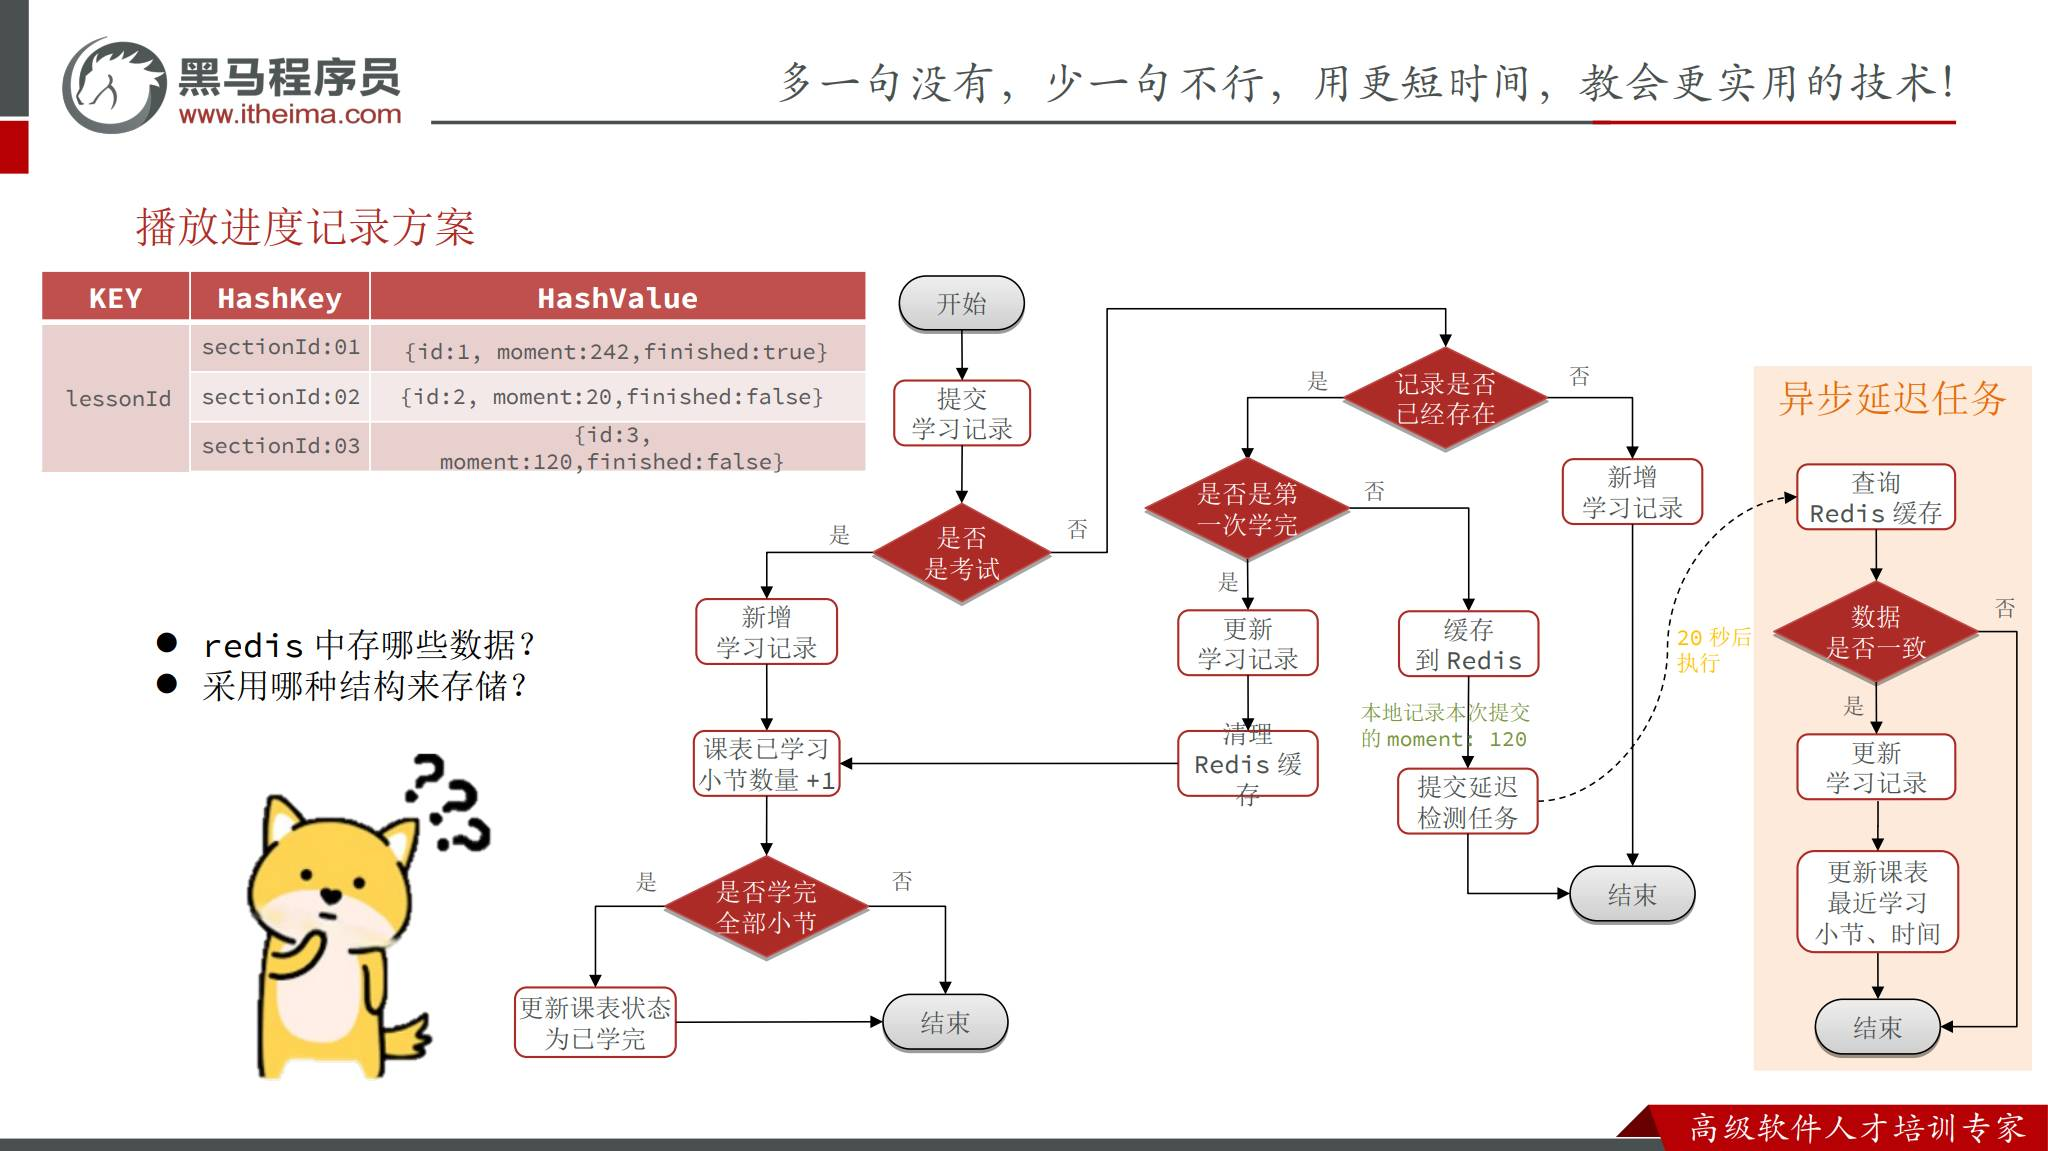

*来源：本章PPT第41页。图中延迟检测间隔为20秒，左侧为记录缓存结构。*

1. 查询旧记录时先查Redis，未命中再查MySQL。
2. 首条视频记录写入MySQL，得到记录ID。原流程默认首条位置为0，首条已达阈值的边界仍需补齐。
3. 已有记录若本次首次完成，立即更新小节状态与课表计数，并处理相关缓存。
4. 其他播放位置写入Redis，同时创建20秒后执行的检测任务，任务携带本次位置快照。
5. 检测时发现缓存已变化，说明有后续报告，旧任务退出。
6. 检测时缓存与快照一致，说明该位置暂时没有变化，将快照写入MySQL并更新课表最近小节/时间，再按实现约定清理缓存。

```text
0秒：位置120，缓存120，任务A将在20秒执行
15秒：位置135，缓存135，任务B将在35秒执行
20秒：A发现120 != 135，退出
35秒：B发现135 == 135，落库135
```

这是“变化停止后保存”的防抖思路。每次报告都有后续任务，旧任务退出后最后一次任务才能完成落库。成功写数据库后再清理脏缓存，失败必须保留可重试状态。


## DelayQueue 与延迟任务的实现

延迟队列让任务在截止时间到达后才可取出。JDK `DelayQueue` 的元素实现 `Delayed`，提供剩余延迟 `getDelay` 与排序 `compareTo`，工作线程通过 `take()` 等待到期任务，避免忙轮询。

```java
// 补充示意，非网盘DelayTask.java原文
final class DelayTask implements Delayed {
    final Long lessonId;
    final Long sectionId;
    final long version;
    final long dueNanos;

    DelayTask(Long lessonId, Long sectionId, long version, long delaySeconds) {
        this.lessonId = lessonId;
        this.sectionId = sectionId;
        this.version = version;
        this.dueNanos = System.nanoTime()
                + TimeUnit.SECONDS.toNanos(delaySeconds);
    }
    @Override
    public long getDelay(TimeUnit unit) {
        return unit.convert(dueNanos - System.nanoTime(), TimeUnit.NANOSECONDS);
    }
    @Override
    public int compareTo(Delayed other) {
        return Long.compare(dueNanos, ((DelayTask) other).dueNanos);
    }
}
```

`System.nanoTime()` 适合测量进程内时间间隔，避免系统日历时钟调整干扰延迟。它不能作为跨进程持久化时间戳。消费者循环取任务、查缓存、判断版本、执行保存，并在停机时正确响应中断；一次业务异常不能让工作线程永久退出。

| 机制 | 特点 | 边界 |
| --- | --- | --- |
| JDK DelayQueue | 本地内存，简单，无需额外中间件 | 进程退出丢任务，各实例队列独立，无内置容量上限 |
| Redis/Redisson延迟队列 | 基于Redis共享任务 | 依赖Redis与消费者可靠性，具体API看版本 |
| 延迟MQ | 借助消息中间件调度与重试 | 需幂等、确认、死信等配套 |
| 时间轮 | 将时间槽循环扫描，适合大量定时任务 | 调度精度与槽间隔有关，本地实现仍不自动持久化 |

PPT举例RocketMQ支持延迟消息、RabbitMQ可通过插件实现。**补充**：RabbitMQ也能组合TTL与死信实现部分延迟场景，插件并非唯一机制。本章用DelayQueue理解流程，不能据此声称已实现持久化调度。


## 优化后仍要解决的一致性问题

Redis合并写降低压力，同时引入数据库暂时滞后的窗口。完整实现要同时保证续播读到新位置、首次完成只统计一次、脏数据最终落库。

| 问题 | 原流程可能出现什么 | 补充改进方向 |
| --- | --- | --- |
| 比较相同moment | 暂停心跳、回退或多设备可能产生相同位置 | 比较递增版本/有效提交序号，不能仅比较位置 |
| 检测后又有新上报 | 旧任务落库后删除新缓存 | 按版本条件清理，使用Lua原子比较与删除 |
| 旧任务晚于完成请求 | 用旧快照覆盖新状态/时间 | 进度版本校验，普通位置写入不能回退finished |
| 持续播放不落库 | 进程重启后本地任务丢失，缓存长期无任务处理 | 最大保存间隔、共享调度、启动补偿扫描 |
| 多实例处理同一记录 | 多个工作线程同时保存/清理 | 共享任务归属或原子版本控制，落库幂等 |
| 读写路径不一致 | DB落后，切换设备续播到旧位置 | 查询合并有效缓存与数据库记录 |
| MySQL写入失败 | 任务消失或缓存先清掉导致数据丢失 | 重试、保留脏标记、失败监控与补偿 |

Lua只能保证Redis内部一组操作的原子性，不能把Redis检查和MySQL写入变成一个原子事务。可靠方案可给持久化记录附带版本，数据库条件写入、Redis条件清理，并通过重试或补偿收敛。

续播的“最后位置”与完成判定的“已达到阈值”要分别保存。用户主动回退到60秒时，简单取所有请求的最大moment虽然避免数值变小，却可能违背最后位置续播的需求。选择最新有效请求时需要顺序依据，而不是永远取最大值。


## 课程过期的 SpringTask 练习

课表状态不会随着时间自动改变。本章练习要求定期检查有效期，把过期课程修改为已失效。SpringTask通过 `@EnableScheduling` 开启，`@Scheduled` 声明执行周期。

```java
// 补充练习示例：按业务约定，只处理未学习/学习中的课程
@Scheduled(cron = "0 */5 * * * ?")
public void expireLessons() {
    lessonService.lambdaUpdate()
        .set(LearningLesson::getStatus, LessonStatus.EXPIRED.getValue())
        .in(LearningLesson::getStatus,
            LessonStatus.NOT_BEGIN.getValue(), LessonStatus.LEARNING.getValue())
        .isNotNull(LearningLesson::getExpireTime)
        .le(LearningLesson::getExpireTime, LocalDateTime.now())
        .update();
}
```

这里每5分钟检查一次是示例选择，`EXPIRED` 的名称需核对实际项目枚举。若项目要求已学完课程也变为过期，调整状态集合；学习完成状态和访问有效期本来可以分开表达，不能默认覆盖历史完成信息。

**补充**：入口仍需实时检查有效期，不能等任务执行才禁止学习。大表分批更新，避免长事务；多实例部署时任务会重复触发，可选择单实例调度、分布式调度或幂等的条件更新，并确认是否允许重复执行。无需为每张课表创建一个本地定时器。


## 自测与验收场景

验收应检查状态转移和统计结果，而不仅是接口能返回200。

| 场景 | 应确认的结果 |
| --- | --- |
| 未报名或已过期查询记录 | 按约定返回空/错误，不能空指针 |
| 用户A提交用户B的lessonId | 拒绝写入 |
| 小节不属于该课程 | 拒绝写入 |
| 视频首次上报0秒，再上报40%、50%、80% | 首次达到50%时计数1次 |
| 视频第一条请求已经60% | 仍能正确完成并计数，不依赖第二次请求 |
| 完成后回退或重看 | finished保持true，finish_time不覆盖 |
| 视频与考试重复请求 | 没有重复行、没有重复计数 |
| 同节并发达标、不同节并发完成 | 计数准确，课程最终状态正确 |
| 周一00:00完成，下周一00:00完成 | 分别计入对应周，不重不漏 |
| 第2页/越界页/无计划 | 汇总覆盖全局，分页字段和空列表一致 |
| Redis连续变化后停止 | 旧任务退出，最新快照最终落库 |
| 服务重启或数据库失败 | 有恢复/重试路径，未落库数据不直接消失 |

可用一门包含两个视频和一个考试的小课程验证整条链路：初始0节，视频达标后1节，重复上报仍1节，第二视频达标2节，考试提交3节，课程变为已学完。计划汇总与本周统计需再核对时间范围和退出列表后的口径。


## 课件勘误与阅读检查清单

整理时保留业务主线，对可能导致实现错误的差异集中记录。

| 原资料现象 | 本笔记处理 |
| --- | --- |
| 文字“超过50%”，代码 `>=` | 采用达到50%，列出恰好一半的例子 |
| 在线DDL缺少 `finish_time` | 采用PPT包含该列的版本，说明迁移需求 |
| 两份DDL的唯一索引不同 | 明确业务假设，区分普通索引与唯一约束 |
| 查询分析含有效期检查，代码缺失 | 查询示例补上，标注原代码限制 |
| 首次新增视频直接返回false | 指出首条高进度漏判 |
| 考试假定只提交一次 | 补充重试与幂等 |
| `freq` 与 `weekFreq` 混用 | 分清DTO请求字段、PO字段与接口表 |
| `weekSections` 与 `weekLearnedSections` 混用 | 采用代码及后期PPT的后者 |
| 最近信息只在 `!finished` 时更新 | 指出首完事件最近信息可能滞后 |
| 周范围使用严格大于起点 | 推荐左闭右开区间 |
| 本周总数与计划列表范围不同 | 说明已完成课程退出列表的影响 |
| 延迟检测仅比较moment | 保留原流程，补充版本与原子清理 |

阅读代码时优先检查：查的是谁的课表、传入的小节是否属于该课程、首次完成依据是否原子、周统计用的是否首次完成时间、缓存读写与最终落库是否配套。


## 面试提示：解释续播与高频写入

**面试提示**：可以用“需求、基线、瓶颈、优化、可靠性”说明设计，而不要把教学方案描述成已经在线上实施的经历。

> 为了让用户突然断开或切换设备后续播，服务端保存每个小节的最新播放位置。前端按约15秒周期上报，普通播放位置可以覆盖更新，小节完成和课程累计完成数量则只在首次状态转移时更新。直接每次写MySQL会放大数据库压力，因此可用Redis Hash保存最新有效快照，配合约20秒的延迟检测合并连续报告。查询优先读取缓存中的新进度。首次完成使用数据库条件更新保证只统计一次，服务重启、多实例、写入失败则需要持久化调度、版本控制、重试和补偿。

若被追问“异步为何能减轻数据库压力”，区分削峰与减少写次数；若被追问“缓存会不会丢”，说明本地DelayQueue不持久化、TTL不能承担可靠落库；若被追问“回退播放”，说明续播位置可回退，完成状态保持，乱序使用有效版本判定。性能数字与最坏误差需要测量，不能凭15秒心跳直接给出绝对保证。
